# 04 — GRU/LSTM em janelas de 30 ciclos (FD001)

**Pergunta:** uma rede recorrente, vendo os últimos 30 ciclos de cada motor, bate o XGBoost `+norm+ciclo` (teste RMSE **10,98**; média de sementes 11,15 ± 0,10)?

Escolhas (e por quê):
- **Janela de 30 ciclos, passo 1:** cada motor de treino gera uma janela por ciclo (a partir do ciclo 30). Mais exemplos, mesma regra do teste.
- **14 sensores úteis:** os outros 7 sensores e as 3 configurações operacionais são constantes (ou quase) no FD001 e só adicionam ruído.
- **RUL de treino limitada em 125 (clip):** o motor praticamente não degrada no começo da vida; prever "250 ciclos restantes" não tem sinal. É o padrão da literatura no C-MAPSS.
- **Validação por motor (80/20):** janelas do mesmo motor são quase idênticas; sortear janelas vazaria informação para a validação. Early stopping usa essa validação, **nunca o teste**.
- **5 sementes:** uma rede treinada uma vez é sorte. O XGBoost foi reportado com média de sementes; aqui também.
- **Teste:** última janela de cada um dos 100 motores de `test_FD001.txt`, comparada com `RUL_FD001.txt`.
- **Duas variantes de entrada:** `sensores` (só os 14 sensores na janela) e `sensores+ciclo` (adiciona o número do ciclo a cada passo). O XGBoost `+norm+ciclo` conhecia a idade absoluta do motor; uma janela de 30 ciclos sozinha não conhece. A segunda variante (só GRU, que foi a melhor) testa se é isso que explica a diferença.

In [ ]:
import json, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# ---------------- configuração ----------------
WINDOW = 30
CLIP = 125
SEEDS = [0, 1, 2, 3, 4]
MAX_EPOCHS = 80
PATIENCE = 12
BATCH = 256
HIDDEN = 64
LAYERS = 2
DROPOUT = 0.2
LR = 1e-3
VAL_FRAC = 0.2

# referência do XGBoost (notebook 03)
XGB_RMSE = 10.98
XGB_MEAN, XGB_STD = 11.15, 0.10

# Métrica principal: "clipped" compara com min(RUL real, 125); "raw" com a RUL real do RUL_FD001.txt.
# Use a MESMA que o notebook 03 usou para chegar em 10,98. As duas são calculadas de qualquer forma.
HEADLINE = "clipped"

DATA_DIR = None  # ex.: Path("../data/raw"); None = procura nos lugares comuns
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.15.0+cpu


In [ ]:
COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
SENSORS = [f"s{i}" for i in (2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21)]

def find_data_dir():
    if DATA_DIR is not None:
        return Path(DATA_DIR)
    for c in ["data/raw", "data", "../data/raw", "../data", ".", "raw", "../raw"]:
        if (Path(c) / "train_FD001.txt").exists():
            return Path(c)
    raise FileNotFoundError("train_FD001.txt não encontrado. Defina DATA_DIR na célula de configuração.")

d = find_data_dir()
read = lambda f: pd.read_csv(d / f, sep=r"\s+", header=None, names=COLS)
train = read("train_FD001.txt").sort_values(["unit", "cycle"])
test = read("test_FD001.txt").sort_values(["unit", "cycle"])
rul_test_raw = np.loadtxt(d / "RUL_FD001.txt").astype(np.float32)

train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train["rul"] = train["rul"].clip(upper=CLIP)

print(d, "| treino:", train.unit.nunique(), "motores,", len(train), "linhas | teste:", test.unit.nunique(), "motores")
assert len(rul_test_raw) == test.unit.nunique()

..\data | treino: 100 motores, 20631 linhas | teste: 100 motores


In [ ]:
VARIANTS = {"sensores": (SENSORS, ["GRU", "LSTM"]), "sensores+ciclo": (SENSORS + ["cycle"], ["GRU"])}

def make_windows(df, feats, w, last_only=False):
    X, y, u = [], [], []
    for unit, g in df.groupby("unit"):
        a = g[feats].to_numpy(np.float32)
        r = g["rul"].to_numpy(np.float32) if "rul" in g else None
        if len(a) < w:  # motor curto: repete a primeira linha no começo
            a = np.vstack([np.repeat(a[:1], w - len(a), axis=0), a])
        starts = [len(a) - w] if last_only else range(len(a) - w + 1)
        for s in starts:
            X.append(a[s:s + w]); u.append(unit)
            if r is not None:
                y.append(r[s + w - 1])
    return np.stack(X), (np.array(y, np.float32) if y else None), np.array(u)

D = {}
for name, (feats, _) in VARIANTS.items():
    sc = StandardScaler().fit(train[feats])  # ajustado só no treino
    tr, te = train.copy(), test.copy()
    tr[feats] = sc.transform(tr[feats]).astype(np.float32)
    te[feats] = sc.transform(te[feats]).astype(np.float32)
    X, y, u = make_windows(tr, feats, WINDOW)
    Xt, _, _ = make_windows(te, feats, WINDOW, last_only=True)
    D[name] = (X, y, u, Xt)
    print(f"{name}: janelas treino {X.shape} | janelas teste {Xt.shape}")
y_test_raw = rul_test_raw
y_test_clip = np.minimum(rul_test_raw, CLIP)

sensores: janelas treino (17731, 30, 14) | janelas teste (100, 30, 14)
sensores+ciclo: janelas treino (17731, 30, 15) | janelas teste (100, 30, 15)


In [ ]:
class RNNReg(nn.Module):
    def __init__(self, kind, n_feat):
        super().__init__()
        cell = nn.GRU if kind == "GRU" else nn.LSTM
        self.rnn = cell(n_feat, HIDDEN, LAYERS, batch_first=True, dropout=DROPOUT)
        self.head = nn.Sequential(nn.Linear(HIDDEN, 32), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)  # último passo da janela

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict(model, X):
    model.eval()
    p = model(torch.from_numpy(X).to(DEVICE)).cpu().numpy() * CLIP
    return np.clip(p, 0, CLIP)

def rmse(p, y):
    return float(np.sqrt(np.mean((p - y) ** 2)))

def nasa_score(p, y):
    d = p - y
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def fit(kind, seed, Xtr, ytr, Xva, yva):
    set_seed(seed)
    model = RNNReg(kind, Xtr.shape[2]).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr / CLIP)),
                    batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(seed))
    best, best_state, bad = float("inf"), None, 0
    for ep in range(MAX_EPOCHS):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            F.mse_loss(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        val = rmse(predict(model, Xva), yva)
        sched.step(val)
        if val < best - 1e-4:
            best, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, best, ep + 1

In [ ]:
from itertools import product
rows, preds = [], {}
t0 = time.time()
for seed, (vname, (feats, kinds)) in product(SEEDS, VARIANTS.items()):
    X_all, y_all, u_all, X_test = D[vname]
    units = np.unique(u_all)
    rng = np.random.RandomState(seed)  # mesma divisão de motores entre variantes e modelos
    val_units = rng.choice(units, size=int(len(units) * VAL_FRAC), replace=False)
    va = np.isin(u_all, val_units)
    for kind in kinds:
        model, val_rmse, n_ep = fit(kind, seed, X_all[~va], y_all[~va], X_all[va], y_all[va])
        p = predict(model, X_test)
        preds[(vname, kind, seed)] = p
        rows.append(dict(variante=vname, modelo=kind, seed=seed, epocas=n_ep, val_rmse=val_rmse,
                         test_rmse_clipped=rmse(p, y_test_clip), test_rmse_raw=rmse(p, y_test_raw),
                         score_nasa=nasa_score(p, y_test_raw)))
        r = rows[-1]
        print(f"{vname:14s} {kind:4s} seed={seed} ep={n_ep:3d} val={val_rmse:6.2f} teste(clip)={r['test_rmse_clipped']:6.2f} "
              f"teste(raw)={r['test_rmse_raw']:6.2f} [{time.time()-t0:5.0f}s]")
res = pd.DataFrame(rows)

sensores       GRU  seed=0 ep= 21 val= 12.94 teste(clip)= 13.85 teste(raw)= 15.15 [  104s]
sensores       LSTM seed=0 ep= 33 val= 13.10 teste(clip)= 14.64 teste(raw)= 15.76 [  177s]
sensores+ciclo GRU  seed=0 ep= 25 val= 11.64 teste(clip)= 13.52 teste(raw)= 14.80 [  321s]
sensores       GRU  seed=1 ep= 32 val= 12.42 teste(clip)= 13.65 teste(raw)= 15.01 [  508s]
sensores       LSTM seed=1 ep= 35 val= 12.95 teste(clip)= 13.46 teste(raw)= 14.54 [  663s]
sensores+ciclo GRU  seed=1 ep= 36 val= 12.14 teste(clip)= 15.93 teste(raw)= 17.31 [  869s]
sensores       GRU  seed=2 ep= 25 val= 13.41 teste(clip)= 13.61 teste(raw)= 15.08 [  943s]
sensores       LSTM seed=2 ep= 22 val= 15.10 teste(clip)= 13.88 teste(raw)= 15.33 [ 1024s]
sensores+ciclo GRU  seed=2 ep= 24 val= 12.65 teste(clip)= 13.82 teste(raw)= 15.54 [ 1098s]
sensores       GRU  seed=3 ep= 21 val= 13.30 teste(clip)= 13.78 teste(raw)= 15.19 [ 1157s]
sensores       LSTM seed=3 ep= 28 val= 13.68 teste(clip)= 13.22 teste(raw)= 14.42 [ 1261s]

In [ ]:
col = f"test_rmse_{HEADLINE}"
summ = res.groupby(["variante", "modelo"]).agg(
    rmse_media=(col, "mean"), rmse_dp=(col, "std"), rmse_min=(col, "min"), rmse_max=(col, "max"),
    raw_media=("test_rmse_raw", "mean"), clip_media=("test_rmse_clipped", "mean"),
    score_medio=("score_nasa", "mean"), val_media=("val_rmse", "mean")).round(2)
print(f"Métrica principal: RMSE de teste ({HEADLINE}) | XGBoost: {XGB_RMSE} (média de sementes {XGB_MEAN} ± {XGB_STD})")
display(summ)

best_var, best_kind = summ["rmse_media"].idxmin()
m, s = summ.loc[(best_var, best_kind), "rmse_media"], summ.loc[(best_var, best_kind), "rmse_dp"]
if m + s < XGB_MEAN - XGB_STD:
    verdict = "supera o XGBoost"
elif m - s > XGB_MEAN + XGB_STD:
    verdict = "não supera o XGBoost"
else:
    verdict = "empata com o XGBoost (diferença dentro do ruído entre sementes)"
print(f"Melhor: {best_kind} ({best_var}) {m:.2f} ± {s:.2f} vs XGBoost {XGB_MEAN} ± {XGB_STD} -> {verdict}")

Métrica principal: RMSE de teste (clipped) | XGBoost: 10.98 (média de sementes 11.15 ± 0.1)


rmse_media  rmse_dp  rmse_min  rmse_max  raw_media  \
variante       modelo                                                       
sensores       GRU          13.72     0.10     13.61     13.85      15.06   
               LSTM         13.83     0.54     13.22     14.64      15.02   
sensores+ciclo GRU          14.02     1.08     13.38     15.93      15.45   

                       clip_media  score_medio  val_media  
variante       modelo                                      
sensores       GRU          13.72       374.33      12.85  
               LSTM         13.83       392.86      13.50  
sensores+ciclo GRU          14.02       402.01      12.15

Melhor: GRU (sensores) 13.72 ± 0.10 vs XGBoost 11.15 ± 0.1 -> não supera o XGBoost


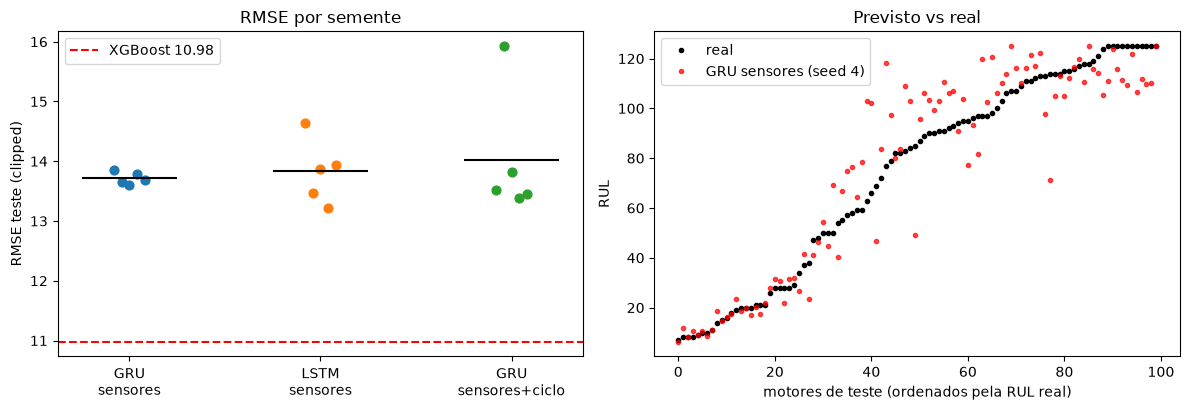

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

for i, (var, kind) in enumerate(summ.index):
    v = res.loc[(res.variante == var) & (res.modelo == kind), col].values
    ax[0].scatter(np.full(len(v), i) + np.linspace(-0.08, 0.08, len(v)), v, s=40)
    ax[0].hlines(v.mean(), i - 0.25, i + 0.25, color="k")
ax[0].axhline(XGB_RMSE, color="r", ls="--", label=f"XGBoost {XGB_RMSE}")
ax[0].set_xticks(range(len(summ)), [f"{b}\n{a}" for a, b in summ.index])
ax[0].set_ylabel(f"RMSE teste ({HEADLINE})"); ax[0].set_title("RMSE por semente"); ax[0].legend()

sub = res[(res.variante == best_var) & (res.modelo == best_kind)].sort_values(col)
seed_med = int(sub.iloc[len(sub) // 2].seed)
p = preds[(best_var, best_kind, seed_med)]
ytrue = y_test_clip if HEADLINE == "clipped" else y_test_raw
o = np.argsort(ytrue)
ax[1].plot(ytrue[o], "k.", label="real")
ax[1].plot(p[o], "r.", alpha=0.7, label=f"{best_kind} {best_var} (seed {seed_med})")
ax[1].set_xlabel("motores de teste (ordenados pela RUL real)"); ax[1].set_ylabel("RUL"); ax[1].legend()
ax[1].set_title("Previsto vs real")
plt.tight_layout()
Path("figures").mkdir(exist_ok=True); Path("results").mkdir(exist_ok=True)
plt.savefig("figures/04_rnn_fd001.png", dpi=150)
plt.show()

res.to_csv("results/04_rnn_fd001.csv", index=False)

In [ ]:
fmt = lambda x: f"{x:.2f}".replace(".", ",")
print("Linha para o README:\n")
print(f"- **04 — {best_kind}, {best_var} (janela de {WINDOW} ciclos):** teste RMSE {fmt(m)} ± {fmt(s)} "
      f"({len(SEEDS)} sementes) vs XGBoost {fmt(XGB_RMSE)}; {verdict}.")

Linha para o README:

- **04 — GRU, sensores (janela de 30 ciclos):** teste RMSE 13,72 ± 0,10 (5 sementes) vs XGBoost 10,98; não supera o XGBoost.
